# Lab 03 - Developing a Tiny Transformer Language Model 

In [1]:
import math
import json
import random
from pathlib import Path

import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import pandas as pd
from datasets import load_dataset


c:\Users\Owner\Downloads\LLM-Practical-Portfolio\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
if device == "cpu":
    torch.set_num_threads(min(4, torch.get_num_threads()))

cwd = Path.cwd()
if cwd.name == "notebooks":
    LAB_DIR = cwd.parent
elif cwd.name == "Lab-03-Tiny-Transformer":
    LAB_DIR = cwd
elif (cwd / "Lab-03-Tiny-Transformer").is_dir():
    LAB_DIR = cwd / "Lab-03-Tiny-Transformer"
else:
    raise FileNotFoundError("Open the notebook from the Lab-03-Tiny-Transformer project folder.")

RESULTS_DIR = LAB_DIR / "results"
CHECKPOINT_DIR = LAB_DIR / "checkpoints"
RESULTS_DIR.mkdir(exist_ok=True)
CHECKPOINT_DIR.mkdir(exist_ok=True)

In [3]:
print("PyTorch:", torch.__version__)
print("Device:", device)
print("Lab directory:", LAB_DIR)

PyTorch: 2.15.0+cpu
Device: cpu
Lab directory: c:\Users\Owner\Downloads\LLM-Practical-Portfolio\Lab-03-Tiny-Transformer


### 1. Load and explore the TinyStories Dataset


In [4]:
NUM_STORIES= 600

stories_dataset = load_dataset(
    "roneneldan/TinyStories",
    split= f"train[:{NUM_STORIES}]"
)

stories = [row["text"] for row in stories_dataset if row["text"].strip()]
assert len(stories) >= 20, "Only few stories were loaded"

print("Number of loaded stories:", len(stories))
for i, story in enumerate(stories[:3], start=1):
    print(f"\nExample story {i} ({len(story)} characters, {len(story.split())} words)")
    print(story[:450])
    print("..." if len(story) > 450 else "")

story_lengths = [len(s) for s in stories]
print("\nMinimum length:", min(story_lengths))
print("Maximum length:", max(story_lengths))


Number of loaded stories: 600

Example story 1 (701 characters, 134 words)
One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with it because it was sharp. Lily wanted to share the needle with her mom, so she could sew a button on her shirt.

Lily went to her mom and said, "Mom, I found this needle. Can you share it with me and sew my shirt?" Her mom smiled and said, "Yes, Lily, we can share the needle and fix your shirt."

Together, they shared the needle and sewed the butto
...

Example story 2 (705 characters, 142 words)
Once upon a time, there was a little car named Beep. Beep loved to go fast and play in the sun. Beep was a healthy car because he always had good fuel. Good fuel made Beep happy and strong.

One day, Beep was driving in the park when he saw a big tree. The tree had many leaves that were falling. Beep liked how the leaves fall and wanted to play with them. Beep drove under the tree and watched the leaves fall on him. He la

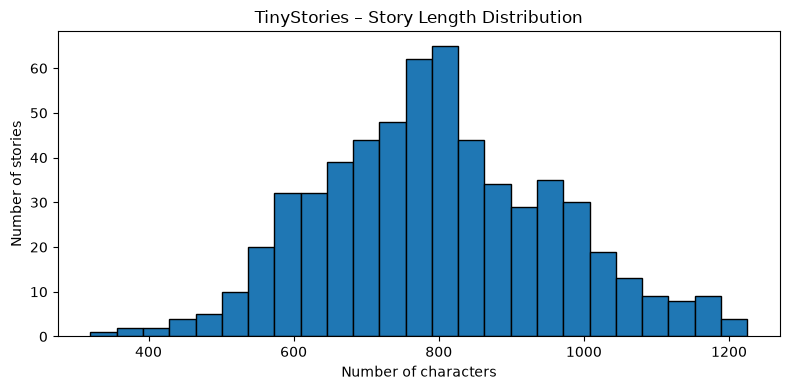

In [5]:
plt.figure(figsize=(8, 4))
plt.hist(story_lengths, bins=25, edgecolor="black")
plt.title("TinyStories – Story Length Distribution")
plt.xlabel("Number of characters")
plt.ylabel("Number of stories")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "story_length_distribution.png", dpi=150)
plt.show()

In [6]:
# Shuffle reproducibly, then split by complete stories.
VAL_FRACTION = 0.10
random.Random(SEED).shuffle(stories)
num_val_stories = max(1, int(len(stories) * VAL_FRACTION))
val_stories = stories[:num_val_stories]
train_stories = stories[num_val_stories:]

print("Training stories:", len(train_stories))
print("Validation stories:", len(val_stories))

Training stories: 540
Validation stories: 60


### 2. Preprocess text with a character-level tokenizer

In [7]:
BLOCK_SIZE= 64
PROMPT = "Once upon a time"


train_text = "\n\n".join(train_stories)
val_text = "\n\n".join(val_stories)

chars = sorted(set(train_text))
stoi = {ch: i + 1 for i, ch in enumerate(chars)}  # ID 0 is unknown
itos = {i + 1: ch for i, ch in enumerate(chars)}
itos[0] = "?"
vocab_size = len(chars) + 1

def encode(text):
    return [stoi.get(ch, 0) for ch in text]

def decode(ids):
    return "".join(itos.get(int(i), "?") for i in ids)

train_data = torch.tensor(encode(train_text), dtype=torch.long)
val_data = torch.tensor(encode(val_text), dtype=torch.long)

print("Vocabulary size (including unknown token):", vocab_size)
print("Training character tokens:", len(train_data))
print("Validation character tokens:", len(val_data))
print("Unseen characters in validation:", sum(ch not in stoi for ch in val_text))
print("Example encoded IDs:", encode(PROMPT))
print("Decoded example:", decode(encode(PROMPT)))

assert len(train_data) > BLOCK_SIZE + 1
assert len(val_data) > BLOCK_SIZE + 1

Vocabulary size (including unknown token): 74
Training character tokens: 430133
Validation character tokens: 49507
Unseen characters in validation: 1
Example encoded IDs: [31, 55, 44, 46, 2, 62, 57, 56, 55, 2, 42, 2, 61, 50, 54, 46]
Decoded example: Once upon a time


### 3.	Preparing training data 

In [8]:
BATCH_SIZE= 16
VAL_BATCHES= 5

def get_batch(split="train", starts=None, generator=None):
    data = train_data if split == "train" else val_data

    if starts is None:
        starts = torch.randint(0, len(data) - BLOCK_SIZE, (BATCH_SIZE,),
                               generator=generator)

    inputs = torch.stack([data[i:i + BLOCK_SIZE] for i in starts])
    targets = torch.stack([data[i + 1:i + BLOCK_SIZE + 1] for i in starts])
    return inputs.to(device), targets.to(device)

# Fixed validation positions give more comparable validation curves each epoch.
val_rng = torch.Generator().manual_seed(SEED)
fixed_val_starts = [
    torch.randint(0, len(val_data) - BLOCK_SIZE, (BATCH_SIZE,), generator=val_rng)
    for _ in range(VAL_BATCHES)
]

sample_x, sample_y = get_batch("train")
print("Input batch shape:", tuple(sample_x.shape))
print("Target batch shape:", tuple(sample_y.shape))
print("Sample input:", repr(decode(sample_x[0][:50].tolist())))
print("Sample target:", repr(decode(sample_y[0][:50].tolist())))
assert torch.equal(sample_x[:, 1:], sample_y[:, :-1]), "Targets must be shifted by one token."

Input batch shape: (16, 64)
Target batch shape: (16, 64)
Sample input: 'n the leash, but Spot was too excited. Then Billy '
Sample target: ' the leash, but Spot was too excited. Then Billy h'


### 4. Build the transformer architecture

- **Token embedding:** Learns a vector for each character ID.
- **Positional embedding:** Adds information about character position.
- **Masked multi-head self-attention:** Allows attention to earlier/current positions, but **not future positions**.
- **Feed-forward network (GELU):** Processes the representation at each position.
- **Residual connections and LayerNorm:** Help gradients and training stability.
- **Language-model head:** Converts hidden representations into next-character scores.

In [10]:
class TransformerBlock(nn.Module):
    def __init__(self, embed_dim, num_heads, ff_dim, dropout):
        super().__init__()
        self.attention = nn.MultiheadAttention(
            embed_dim=embed_dim,
            num_heads=num_heads,
            dropout=dropout,
            batch_first=True
        )
        self.norm1 = nn.LayerNorm(embed_dim)
        self.norm2 = nn.LayerNorm(embed_dim)
        self.dropout = nn.Dropout(dropout)
        self.feed_forward = nn.Sequential(
            nn.Linear(embed_dim, ff_dim),
            nn.GELU(),
            nn.Linear(ff_dim, embed_dim)
        )

    def forward(self, x, causal_mask):
        attended, _ = self.attention(
            x, x, x,
            attn_mask=causal_mask,
            need_weights=False
        )
        x = self.norm1(x + self.dropout(attended))  # residual connection
        x = self.norm2(x + self.dropout(self.feed_forward(x)))
        return x


class TinyTransformer(nn.Module):
    def __init__(self, vocab_size, block_size, embed_dim=64,
                 num_heads=2, num_layers=2, ff_dim=128, dropout=0.1):
        super().__init__()
        if embed_dim % num_heads != 0:
            raise ValueError("embed_dim must be divisible by num_heads")
        self.block_size = block_size
        self.token_embedding = nn.Embedding(vocab_size, embed_dim)
        self.position_embedding = nn.Embedding(block_size, embed_dim)
        self.blocks = nn.ModuleList([
            TransformerBlock(embed_dim, num_heads, ff_dim, dropout)
            for _ in range(num_layers)
        ])
        self.final_norm = nn.LayerNorm(embed_dim)
        self.lm_head = nn.Linear(embed_dim, vocab_size)

    def forward(self, token_ids):
        B, T = token_ids.shape
        if T > self.block_size:
            raise ValueError("Sequence longer than block_size")

        positions = torch.arange(T, device=token_ids.device)
        x = self.token_embedding(token_ids) + self.position_embedding(positions)

        causal_mask = torch.triu(
            torch.ones(T, T, dtype=torch.bool, device=token_ids.device),
            diagonal=1
        )
        for block in self.blocks:
            x = block(x, causal_mask)

        return self.lm_head(self.final_norm(x))



### 5. Initialize the model

In [11]:
EMBED_DIM = 64
NUM_HEADS = 2
NUM_LAYERS = 2
FF_DIM = 128
DROPOUT = 0.10
LEARNING_RATE = 0.001

model_config = {
    "vocab_size": vocab_size,
    "block_size": BLOCK_SIZE,
    "embed_dim": EMBED_DIM,
    "num_heads": NUM_HEADS,
    "num_layers": NUM_LAYERS,
    "ff_dim": FF_DIM,
    "dropout": DROPOUT
}

torch.manual_seed(SEED)
model = TinyTransformer(**model_config).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)
num_parameters = sum(p.numel() for p in model.parameters())

print("Model parameters:", num_parameters)
print("Optimizer:", optimizer.__class__.__name__)
print("Loss function: CrossEntropyLoss")

with torch.no_grad():
    test_logits = model(sample_x)
print("Logit shape:", tuple(test_logits.shape))
assert test_logits.shape == (BATCH_SIZE, BLOCK_SIZE, vocab_size)

# Check that changing a FUTURE token does not affect predictions at earlier positions.
model.eval()  # disable dropout during this deterministic test
with torch.no_grad():
    probe = sample_x[:1].clone()
    changed_probe = probe.clone()
    changed_probe[:, -1] = (changed_probe[:, -1] + 1) % vocab_size
    original_logits = model(probe)
    changed_logits = model(changed_probe)
assert torch.allclose(original_logits[:, :-1, :],
                      changed_logits[:, :-1, :], atol=1e-5), "Causal masking test failed"
model.train()
print("Causal masking test: PASSED (future token cannot influence earlier logits)")


Model parameters: 80714
Optimizer: AdamW
Loss function: CrossEntropyLoss
Logit shape: (16, 64, 74)
Causal masking test: PASSED (future token cannot influence earlier logits)


### 6. Train the Transformer model

In [12]:
EPOCHS= 12
STEPS_PER_EPOCH = 50

@torch.no_grad()
def evaluate_model(net):
    was_training = net.training
    net.eval()
    losses = []
    for starts in fixed_val_starts:
        x, y = get_batch("val", starts=starts)
        logits = net(x)
        loss = F.cross_entropy(logits.reshape(-1, vocab_size), y.reshape(-1))
        losses.append(loss.item())
    net.train(was_training)
    return sum(losses) / len(losses)

def train_model(net, optimizer, epochs=EPOCHS, steps_per_epoch=STEPS_PER_EPOCH):
    # Separate random generator ensures both models see identical training windows,
    # even if different numbers of layers consume different dropout randomness.
    train_rng = torch.Generator().manual_seed(SEED + 1)
    history = []

    for epoch in range(1, epochs + 1):
        net.train()
        running_loss = 0.0
        for step in range(steps_per_epoch):
            x, y = get_batch("train", generator=train_rng)
            logits = net(x)
            loss = F.cross_entropy(logits.reshape(-1, vocab_size), y.reshape(-1))

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            running_loss += loss.item()

        train_loss = running_loss / steps_per_epoch
        val_loss = evaluate_model(net)
        history.append({"epoch": epoch, "train_loss": train_loss,
                        "val_loss": val_loss})
        print(f"Epoch {epoch:02d} | Train loss: {train_loss:.4f} | Validation loss: {val_loss:.4f}")

    return pd.DataFrame(history)


baseline_history = train_model(model, optimizer)
baseline_history.to_csv(RESULTS_DIR / "baseline_training_history.csv", index=False)

Epoch 01 | Train loss: 3.1885 | Validation loss: 2.7102
Epoch 02 | Train loss: 2.6266 | Validation loss: 2.5048
Epoch 03 | Train loss: 2.4982 | Validation loss: 2.4135
Epoch 04 | Train loss: 2.4202 | Validation loss: 2.3577
Epoch 05 | Train loss: 2.3825 | Validation loss: 2.3217
Epoch 06 | Train loss: 2.3408 | Validation loss: 2.2774
Epoch 07 | Train loss: 2.3053 | Validation loss: 2.2356
Epoch 08 | Train loss: 2.2626 | Validation loss: 2.1931
Epoch 09 | Train loss: 2.2155 | Validation loss: 2.1592
Epoch 10 | Train loss: 2.1845 | Validation loss: 2.1154
Epoch 11 | Train loss: 2.1470 | Validation loss: 2.0808
Epoch 12 | Train loss: 2.1253 | Validation loss: 2.0380


In [24]:
baseline_history.to_csv(
    RESULTS_DIR / "training_history_6_epochs.csv",
    index=False
)


### Observations

The Tiny Transformer was initially trained for 6 epochs using the TinyStories dataset.

The training loss decreased from **2.4752 to 2.2393**, while validation loss decreased from **2.4340 to 2.1991**.

Both curves showed a consistent downward trend, indicating that the model was learning patterns from the training data and improving its next-character predictions on the validation dataset.

The validation loss remained slightly lower than the training loss throughout the experiment. This may be influenced by differences in how training and validation losses were calculated.

No clear evidence of overfitting was observed because validation loss continued to decrease.

However, neither loss curve had stabilised by Epoch 6, suggesting that additional training could improve performance.

**Conclusion:** Six epochs were sufficient to demonstrate learning, but further training is recommended to investigate whether the model can achieve lower validation loss and perplexity.


In [14]:
baseline_history.to_csv(
    RESULTS_DIR / "training_history_12_epochs.csv",
    index=False
)


### 12-Epoch Experiment

The Tiny Transformer was trained for 12 epochs to investigate whether increasing the training duration would improve next-character prediction performance.

#### Training Results

| Metric | Epoch 1 | Epoch 12 |
|---|---:|---:|
| Training Loss | 3.1885 | 2.1253 |
| Validation Loss | 2.7102 | 2.0380 |

#### Observations

Both training and validation losses decreased consistently throughout the 12 epochs.

The training loss decreased from **3.1885 to 2.1253**, while validation loss decreased from **2.7102 to 2.0380**.

The continued reduction in validation loss indicates that the model was improving its predictions on the validation dataset. No clear evidence of overfitting was observed.

Compared with the previous 6-epoch experiment, the new model achieved a lower final validation loss (2.0380 compared with 2.1991). However, differences in the initial losses suggest that the experimental conditions should be checked before attributing the improvement entirely to the increased number of epochs.

Within the 12-epoch experiment itself, validation loss decreased from 2.2774 at Epoch 6 to 2.0380 at Epoch 12, demonstrating the benefit of continued training.

#### Conclusion

Increasing the training duration allowed the Tiny Transformer to achieve lower training and validation losses.

The results suggest that additional training can improve next-character prediction performance, although the quality of generated stories must also be evaluated.

The model had not clearly converged by Epoch 12, indicating that further training could potentially improve performance.


### 7. Monitor training

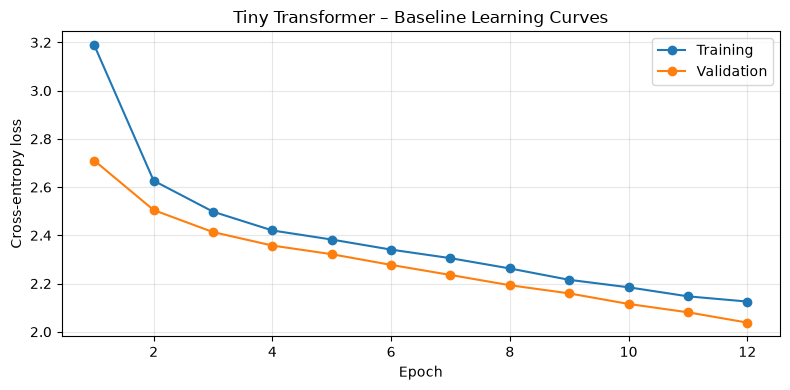

In [15]:
plt.figure(figsize=(8, 4))
plt.plot(baseline_history["epoch"], baseline_history["train_loss"], marker="o", label="Training")
plt.plot(baseline_history["epoch"], baseline_history["val_loss"], marker="o", label="Validation")
plt.title("Tiny Transformer – Baseline Learning Curves")
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "baseline_loss_curves.png", dpi=150)
plt.show()

### 8. Evaluate the model

For this character-level model, perplexity is calculated as `exp(validation_loss)`; it is **character-level perplexity**, not word-level perplexity. It is meaningful when comparing these models because they use the same tokenizer and validation data.

In [16]:
baseline_val_loss = evaluate_model(model)
baseline_perplexity = math.exp(baseline_val_loss)

print(f"Baseline validation loss: {baseline_val_loss:.4f}")
print(f"Baseline character-level perplexity: {baseline_perplexity:.2f}")

Baseline validation loss: 2.0380
Baseline character-level perplexity: 7.68


### 9. Generate new stories

In [17]:
@torch.no_grad()
def generate_story(net, prompt, max_new_chars=160, temperature=0.8, top_k=10, seed=123):
    if not prompt.strip():
        raise ValueError("Please enter a non-empty prompt.")
    if temperature <= 0:
        raise ValueError("temperature must be greater than zero")

    torch.manual_seed(seed)
    net.eval()
    tokens = torch.tensor([encode(prompt)], dtype=torch.long, device=device)

    for _ in range(max_new_chars):
        context = tokens[:, -BLOCK_SIZE:]
        logits = net(context)[:, -1, :] / temperature
        if top_k is not None:
            k = min(top_k, logits.shape[-1])
            top_values, _ = torch.topk(logits, k)
            logits[logits < top_values[:, [-1]]] = -float("inf")
        probabilities = F.softmax(logits, dim=-1)
        next_token = torch.multinomial(probabilities, num_samples=1)
        tokens = torch.cat([tokens, next_token], dim=1)

    return decode(tokens[0].tolist())


baseline_sample = generate_story(model, PROMPT, seed=123)
second_sample = generate_story(model, "The little boy", seed=456)

print("Baseline generation 1:\n", baseline_sample)
print("\nBaseline generation 2:\n", second_sample)

(RESULTS_DIR / "baseline_generated_stories.txt").write_text(
    f"Prompt: {PROMPT}\n{baseline_sample}\n\nPrompt: The little boy\n{second_sample}\n",
    encoding="utf-8"
)

Baseline generation 1:
 Once upon a time. He ging he sed canle so sherand buld to the wes was and sand sanderound or and. Hed aned on a the salk was was oler the she pon ing. The so be wame. He thagan

Baseline generation 2:
 The little boy tomen said,, a ther mime andim ther at sun, "

The a be proow a for has a the fof thount he whe fet sand himy and and she was, so to here so splound was to lom


401


### 9. Results and Observations

After training the Tiny Transformer, I tested its text generation ability using two starting prompts:

1. "Once upon a time"
2. "The little boy"

The model successfully generated additional text using character-level next-token prediction.

#### Observations

The generated text contained several correctly formed English words, including "the", "was", "and", and "he". This suggests that the model learned basic character sequences and commonly occurring word patterns from the TinyStories dataset.

However, the generated stories were not fully meaningful or grammatically correct. The model produced invented words such as "tomen", "thagan", and "splound".

Repetition was also noticeable, particularly with common words such as "and" and "was".

Although the model generated some sentence-like structures and punctuation, the outputs did not follow a coherent storyline.

#### Limitations

The limited quality of the generated text may be influenced by:

- The small training dataset of 600 stories.
- The relatively small Transformer architecture.
- Character-level tokenization, which requires the model to learn how to construct words from individual characters.
- Limited training duration and context length.

#### Conclusion

The experiment demonstrated that the Tiny Transformer successfully learned to generate text by predicting characters sequentially.

However, the results highlight the difference between learning basic character patterns and generating coherent natural language.

Further training, additional data, and improvements to the model configuration may help improve text generation quality.


### 10. Change One Model Setting and Compare Results

**Controlled experiment:** Compare the baseline with **2 Transformer layers** against a simpler model with **1 layer**. Keep the dataset, tokenization, embedding dimension, number of attention heads, optimizer, batch size and training duration the same. The models are independently trained from scratch and compared on the **same fixed validation samples**.

In [20]:
experiment_config = dict(model_config)
experiment_config["num_layers"] = 1

torch.manual_seed(SEED)
experiment_model = TinyTransformer(**experiment_config).to(device)
experiment_optimizer = torch.optim.AdamW(experiment_model.parameters(), lr=LEARNING_RATE)
experiment_history = train_model(experiment_model, experiment_optimizer)
experiment_history.to_csv(RESULTS_DIR/"onelayer_training_history.csv", index=False)

experiment_val_loss = evaluate_model(experiment_model)
experiment_perplexity = math.exp(experiment_val_loss)
experiment_sample = generate_story(experiment_model, PROMPT, seed= 123)

comparison = pd.DataFrame([
    {"model": "2 layers (baseline)", "layers": 2,
     "parameters": sum(p.numel() for p in model.parameters()),
     "validation_loss": baseline_val_loss, "perplexity": baseline_perplexity},
    {"model": "1 layer (experiment)", "layers": 1,
     "parameters": sum(p.numel() for p in experiment_model.parameters()),
     "validation_loss": experiment_val_loss, "perplexity": experiment_perplexity},
])
print("\nModel settings comparison:")
display(comparison.round(4))
comparison.to_csv(RESULTS_DIR / "model_settings_comparison.csv", index=False)
print("\nText from 1-layer model:\n", experiment_sample)

(RESULTS_DIR / "settings_generated_stories.txt").write_text(
    "2-layer baseline:\n" + baseline_sample +
    "\n\n1-layer experiment:\n" + experiment_sample + "\n",
    encoding="utf-8"
)


Epoch 01 | Train loss: 3.3340 | Validation loss: 2.8013
Epoch 02 | Train loss: 2.7001 | Validation loss: 2.5831
Epoch 03 | Train loss: 2.5615 | Validation loss: 2.4749
Epoch 04 | Train loss: 2.4726 | Validation loss: 2.4143
Epoch 05 | Train loss: 2.4325 | Validation loss: 2.3744
Epoch 06 | Train loss: 2.3843 | Validation loss: 2.3304
Epoch 07 | Train loss: 2.3507 | Validation loss: 2.2940
Epoch 08 | Train loss: 2.3142 | Validation loss: 2.2500
Epoch 09 | Train loss: 2.2658 | Validation loss: 2.2098
Epoch 10 | Train loss: 2.2365 | Validation loss: 2.1751
Epoch 11 | Train loss: 2.1953 | Validation loss: 2.1448
Epoch 12 | Train loss: 2.1848 | Validation loss: 2.1170

Model settings comparison:


,model,layers,parameters,validation_loss,perplexity
0,2 layers (baseline),2,80714,2.038,7.6751
1,1 layer (experiment),1,47242,2.117,8.3064



Text from 1-layer model:
 Once upon a time ber sing he sed canl a ad herand buld, outhe weran seredivend s wome thie the w. bupy ter omed there an wicen wan an t ased washalis. s sherer t wad. bint aid 


393

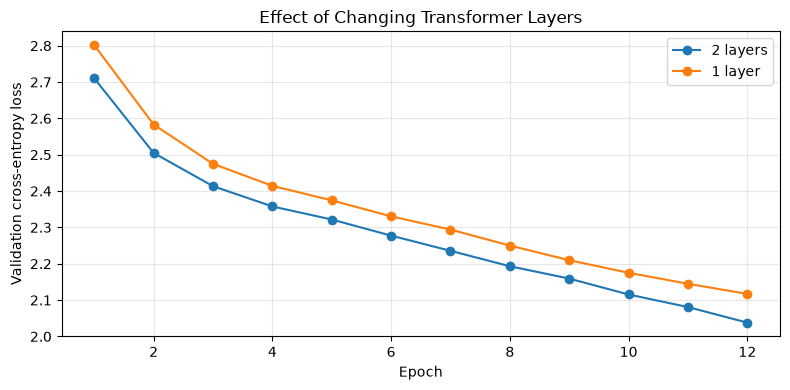

In [21]:
plt.figure(figsize=(8, 4))
plt.plot(baseline_history["epoch"], baseline_history["val_loss"], marker="o", label="2 layers")
plt.plot(experiment_history["epoch"], experiment_history["val_loss"], marker="o", label="1 layer")
plt.xlabel("Epoch")
plt.ylabel("Validation cross-entropy loss")
plt.title("Effect of Changing Transformer Layers")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "model_settings_comparison.png", dpi=150)
plt.show()


### Experiment with Transformer Model Settings

#### Objective

The objective of this experiment was to investigate how changing the number of Transformer layers affects model performance and text generation quality.

Two configurations were evaluated:

- **Baseline Model:** 2 Transformer layers
- **Experimental Model:** 1 Transformer layer

Both models were trained for 12 epochs using the TinyStories dataset.

#### Model Comparison Results

| Metric | 2-Layer Model | 1-Layer Model |
|---|---:|---:|
| Parameters | 80,714 | 47,242 |
| Training Loss | 2.1253 | 2.1848 |
| Validation Loss | 2.0380 | 2.1170 |
| Perplexity | 7.6751 | 8.3064 |

#### Observations

**1. Training Performance**

Both models showed decreasing training and validation losses throughout the 12 epochs, indicating that they successfully learned character patterns from the training data.

The 2-layer model achieved a lower final training loss (2.1253) compared with the 1-layer model (2.1848).

**2. Validation Loss and Perplexity**

The 2-layer Transformer achieved a lower validation loss of 2.0380 and perplexity of 7.6751.

The 1-layer model achieved a validation loss of 2.1170 and perplexity of 8.3064.

These results suggest that the additional Transformer layer improved next-character prediction performance under the tested configuration.

**3. Model Complexity**

The 2-layer model contained 80,714 parameters, while the 1-layer model contained 47,242 parameters.

Removing one Transformer layer reduced the parameter count by approximately 41.5%.

This demonstrates a trade-off between model complexity and predictive performance.

**4. Generated Text Quality**

Both models successfully generated text using starting prompts.

However, the generated stories contained invented words, repeated expressions, and incomplete sentence structures.

The 1-layer model produced text such as "ber sing he sed canl" and "s sherer t wad", demonstrating limited grammatical consistency.

Although the 2-layer model achieved better validation metrics, neither model generated a fully coherent storyline.

#### Conclusion

The experiment demonstrated that increasing the number of Transformer layers improved validation loss and perplexity.

The 2-layer model achieved better predictive performance but required more trainable parameters.

The 1-layer model was smaller but produced slightly weaker evaluation results.

Overall, this experiment helped me understand how Transformer depth influences model capacity, prediction performance, and computational requirements.

The results also showed that lower validation loss does not automatically guarantee coherent text generation.


### 11. Save the trained model

In [22]:
checkpoint_path = CHECKPOINT_DIR / "tiny_transformer_checkpoint.pt"
checkpoint = {
    "model_state_dict": model.state_dict(),
    "config": model_config,
    "chars": chars,
    "seed": SEED,
    "dataset": "roneneldan/TinyStories",
    "training_stories": len(train_stories),
    "validation_stories": len(val_stories),
    "final_validation_loss": baseline_val_loss,
    "final_validation_perplexity": baseline_perplexity
}
torch.save(checkpoint, checkpoint_path)

# Human-readable configuration for the portfolio.
(CHECKPOINT_DIR / "model_config.json").write_text(
    json.dumps({
        "architecture": model_config,
        "training": {"epochs": EPOCHS, "steps_per_epoch": STEPS_PER_EPOCH,
                     "batch_size": BATCH_SIZE, "learning_rate": LEARNING_RATE,
                     "num_stories": len(stories), "seed": SEED},
        "tokenizer": "character level; 0 = unknown character",
        "dataset": "roneneldan/TinyStories"
    }, indent=2),
    encoding="utf-8"
)

# Verify checkpoint can restore a fresh model. Only load checkpoints you trust.
loaded = torch.load(checkpoint_path, map_location=device, weights_only=True)
restored_model = TinyTransformer(**loaded["config"]).to(device)
restored_model.load_state_dict(loaded["model_state_dict"])
restored_model.eval()

assert len(loaded["chars"]) + 1 == loaded["config"]["vocab_size"]
restored_sample = generate_story(restored_model, PROMPT, seed=123)
assert restored_sample == baseline_sample, "Reloaded model should reproduce the seeded generation."

print("Saved checkpoint:", checkpoint_path)
print("Checkpoint size (MB):", round(checkpoint_path.stat().st_size / 1_000_000, 2))
print("Reload check: PASSED")
print("\nText generated after reloading:\n", restored_sample)

Saved checkpoint: c:\Users\Owner\Downloads\LLM-Practical-Portfolio\Lab-03-Tiny-Transformer\checkpoints\tiny_transformer_checkpoint.pt
Checkpoint size (MB): 0.34
Reload check: PASSED

Text generated after reloading:
 Once upon a time. He ging he sed canle so sherand buld to the wes was and sand sanderound or and. Hed aned on a the salk was was oler the she pon ing. The so be wame. He thagan
